## Visualizing Fire Scars from the Eaton and Palisades Fires 

Author: Kate Frankland 

Date: November 21, 2026 

Github: [Github Repo]("https://github.com/katefrankland/eds220-hwk4.git")


# (1) About

## Purpose 
The purpose of this notebook is to visualize the Eaton and Palisades fires that took place in Los Angeles County in 2025. False color imagery is used to overlay the two fire perimeters and see where burn scars are present. This is important because infrared bands can help distinguish burned areas better than true color imagery.

## Highlights
 - Using xarray and rioxarray tools to explore data and restore the CRS.
 - Exploring false color imagery using infrared bands to see where burn scars are present.
 - Reprojecting both fire perimeters to match the raster CRS and then overlaying them to the false color image.

## Data

For this assignment, Landsat 8 satellite data and Perimeter data for the Palisades and Eaton fires are being used. 

(1) The Landsat 8 satellite data was provided in a Google Drive link for the purpose of this assignment, but was originally sourced from the Microsoft Planetary Computer data catalog. This data uses five different bands, and is focused on the Los Angeles County area for the visualization. 

(2) The Palisades and Eaton fire perimeter data is sourced from ArcGIS, providing boundary information. 


# References

- County of Los Angeles. (2025). Palisades and Eaton dissolved fire perimeters [Dataset]. ArcGIS Hub. [ArcGIS link]("https://hub.arcgis.com/maps/")

- NASA. (2025, December 8). Why is that forest red and that cloud blue? How to interpret a false-color satellite image. https://science.nasa.gov/earth/earth-observatory/how-to-interpret-a-false-color-satellite-image/

- U.S. Geological Survey. (2025). Landsat Collection 2 Level-2 [Dataset]. Microsoft Planetary Computer. https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2

Importing Packages and Loading Data 

In [6]:
# Import packages 
import pandas as pd 
import os 
import numpy as np 
import geopandas as gpd 
import xarray as xr 
import rioxarray
import matplotlib.pyplot as plt

(2) Fire Perimeter Data Exploration 
Explore the fire perimeter data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include, at least, the CRS of the data and whether this is projected or geographic.

In [7]:
# Import the Eaton data 
eaton_fp = os.path.join('data', 'eaton_data', 'Eaton_Perimeter_20250121.shp')
eaton = gpd.read_file(eaton_fp)
eaton.head()

# Find the CRS 
print(f"Eaton CRS:", eaton.crs)

# Seeing if it is projected or geogaphic 
print('Is Eaton geographic?: ', eaton.crs.is_geographic)
print('Is Eaton projected?: ', eaton.crs.is_projected)

Eaton CRS: EPSG:4269
Is Eaton geographic?:  True
Is Eaton projected?:  False


In [8]:
# Import Palisades data 
palisades_fp = os.path.join('data', 'palisades_data', 'Palisades_Perimieter_20250121.shp')
palisades = gpd.read_file(palisades_fp)
palisades.head()

# Finding the CRS of the data 
print(f"Palisades CRS", palisades.crs)

# Seeing if it is projected or geographic 
print('Is Palisades geographic?: ', palisades.crs.is_geographic)
print('Is Palisades projected?: ', palisades.crs.is_projected)

Palisades CRS EPSG:4269
Is Palisades geographic?:  True
Is Palisades projected?:  False


In [9]:
eaton.plot() 

<Axes: >

<Axes: >

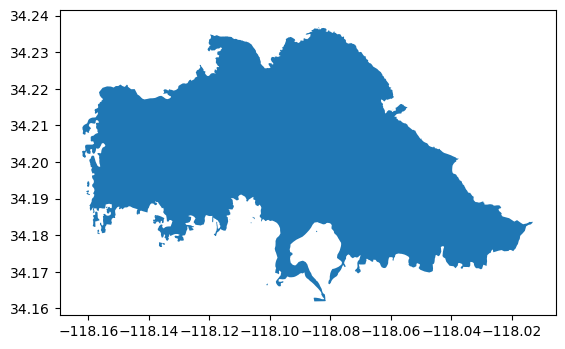

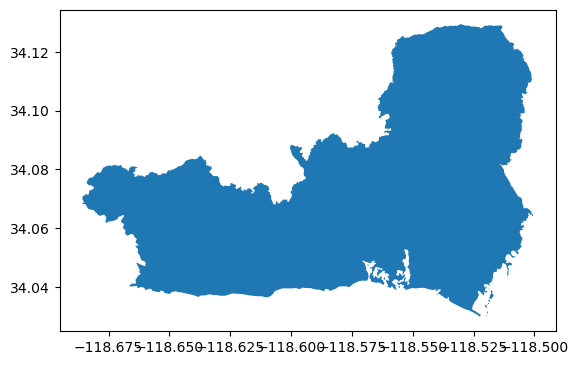

In [10]:
palisades.plot()

In [11]:
eaton.head()

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LAC,EATON,Heat Perimeter,00009087,{72660ADC-B5EF-4D96-A33F-B4EA3740A4E3},2025-01-08T00:00:00Z,...,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026,"MULTIPOLYGON (((-118.10093 34.16680, -118.1008..."


Data Exploration Summary:

The Eaton and Palisades datasets both include the fire year, fire name, agency, GIS-calculated acreage, shape area, shape length, and perimeter geometry. Both datasets use NAD83 (EPSG:4269), a geographic coordinate reference system, not a projected one. This means the perimeter coordinates are stored as longitude and latitude in degrees.

(3) NetCDF data import and exploration 

(a) import the Landsat data using xr.open_dataset()

In [12]:
landsat = xr.open_dataset('data/landsat8-2025-02-23-palisades-eaton.nc')
landsat

sh: 1: getfattr: not found


<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

(b) Explore the data 

The Landsat dataset contains five spectral bands: red, green, blue, near-infrared (nir08), and shortwave infrared (swir22). It also contains spatial_ref, which stores coordinate reference system (CRS) information and is not a spectral band. Each band has two dimensions: y (1,418 rows) and x (2,742 columns). The x and y coordinates give the locations of the pixels, and time is given in a single coordinate.





(4) Restoring geospatial information 

(a) Use rio.crs to print the CRS of this dataset. Is this a geospatial object? 

In [13]:
print(landsat.rio.crs)

None


(b) You may have noticed in section 3 that the geospatial information for this dataset is stored in the variable spatial_ref. Print the CRS by accessing the spatial_ref.crs_wkt attribute of the dataset.

In [14]:
print(landsat.spatial_ref.crs_wkt)
landsat_crs = landsat.spatial_ref.crs_wkt

PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


(c) Recover the geospatial information by using rio.write_crs() and the spatial reference information from part b.

In [15]:
landsat = landsat.rio.write_crs(landsat_crs)

(d) Print the CRS of the updated dataset.

In [16]:
print(landsat.rio.crs)

EPSG:32611


# (5) True Color Image 

(a) Without creating any new variables:
- select the red, green, and blue variables (in that order) of the xarray.Dataset holding the Landsat data
- convert it to an xarray.DataArray using the to_dataarray() method, and then
- use .plot.imshow() to create an RGB image with the data. There will be a warning; that’s ok.

(b) Adjust the scale used for plotting the bands to get a true color image. HINT: Check the robust parameter.

/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


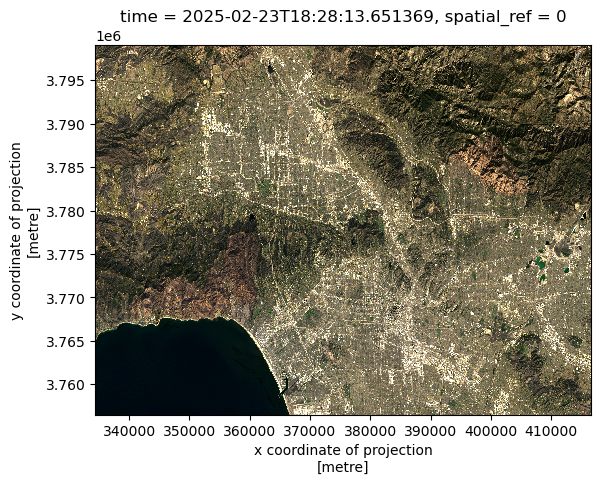

/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


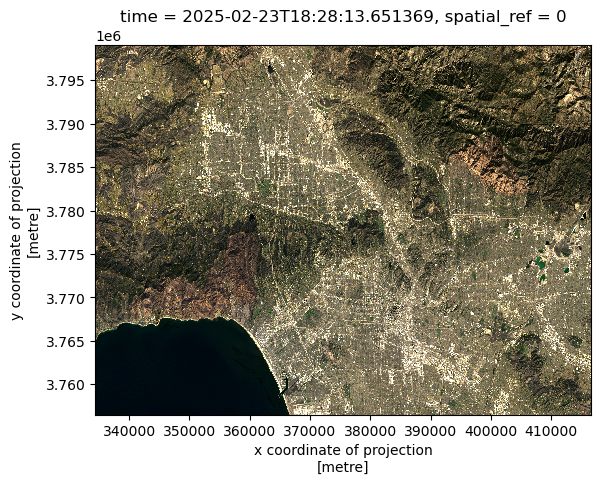

In [18]:
landsat[['red', 'green', 'blue']].to_dataarray(dim='band').plot.imshow(
    x = 'x', 
    y = 'y', 
    rgb = 'band',
    robust = 'True')

(c) To resolve the other warning, identify which bands have nan values. HINT: There are many ways of doing so. One option is to use numpy.isnan().

In [51]:
# Summing the na values in the landset bands 
np.isnan(landsat).sum()

<xarray.Dataset> Size: 56B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          int64 8B 0
    green        int64 8B 1
    blue         int64 8B 109
    nir08        int64 8B 0
    swir22       int64 8B 0

(d) Use the .fillna() method for xarray.Datasets to replace any nan values in the Landsat data with zero.

In [22]:
# Replace missing values with zero 
landsat_new = landsat.fillna(0)

(e) Create a new true color image that gets plotted without warnings.

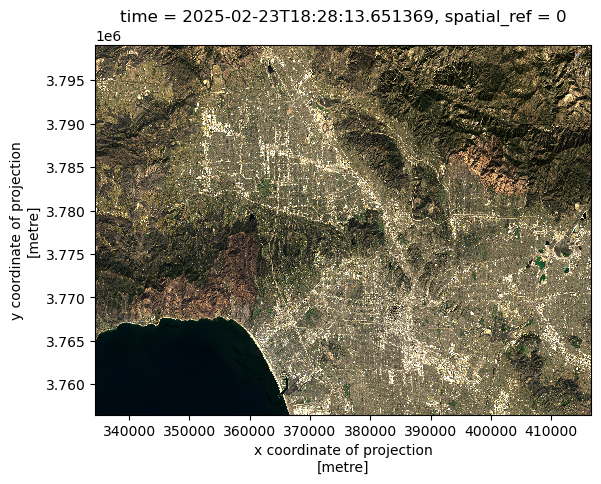

In [23]:
landsat_new[['red', 'green', 'blue']].to_dataarray(dim = 'band').plot.imshow(
    x = 'x', 
    y = 'y', 
    rgb = 'band',
    robust = True)

- Looking at images a and e, there is little difference between them.  From looking at the data variabes, we can see that there is a green band with one missing value and that the blue band has 109 missing values. Replacing these values removed the warning, but it is difficult to distinguish changes in the images themselves. 

# (6) False Color Image 
- Without creating any new variables, create a false color image by plotting the shortwave infrared (swir22),  near-infrared, and red variables (in that order).

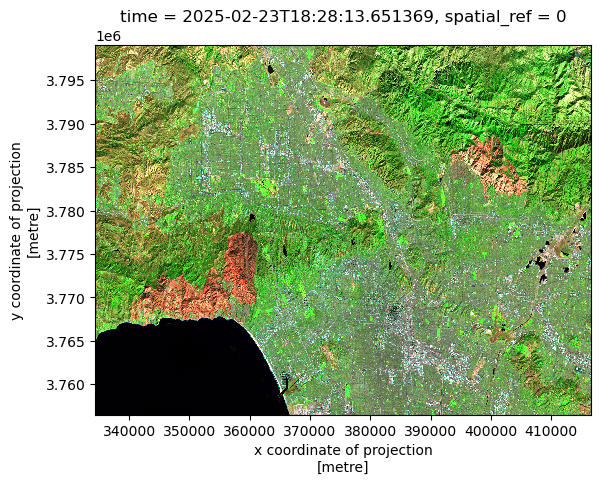

In [54]:
landsat[['swir22', 'nir08', 'red']].to_dataarray(dim = 'band').plot.imshow(
    x = 'x', 
    y = 'y',
    rgb = 'band', 
    robust = True)

# (7) Map 

(a) Create a map showing the shortwave infrared/near-infrared/red false color image together with both fire perimeters. Customize it appropriately including, at least, an informative title and legend. You may also want to include text on the map to identify which fire is which.

(b) 
Write a figure description for the map including a brief explanation of how false color imagery is being used.

In [59]:
# Reproject perimiters, match CRS 
eaton = eaton.to_crs(landsat.rio.crs)
palisades = palisades.to_crs(landsat.rio.crs)

# match with assert 
assert landsat.rio.crs == eaton.crs
assert landsat.rio.crs == palisades.crs

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


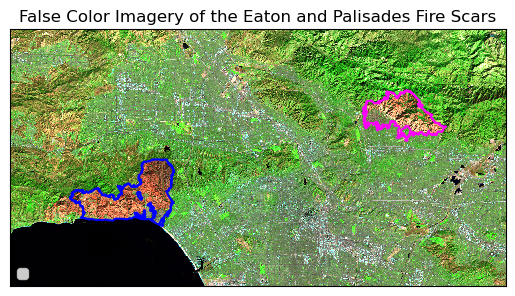

In [63]:
# Plot
fig, ax = plt.subplots()  # Create figure and axes

# False imagery code 
landsat_new[['swir22', 'nir08', 'red']].to_dataarray(dim='band').plot.imshow(
    x = 'x',
    y = 'y',
    rgb = 'band', 
    ax = ax,
    robust = True)

# Perimeters for eaton and palisades 
palisades.boundary.plot(ax=ax, color='blue', linewidth=1.5)
eaton.boundary.plot(ax=ax, color='magenta', linewidth=1.5)

ax.legend(loc = 'lower left')
ax.set_title("False Color Imagery of the Eaton and Palisades Fire Scars")

    
# Remove axes ticks
ax.set_xticks([])  
ax.set_yticks([])  

# Remove axes labels
ax.set_xlabel("")  
ax.set_ylabel("")  

plt.show()

Using false color imagery here, we can more clearly see the burn scars of the two fires. The blue outline marks the Palisades Fire perimeter, and the magenta outline marks the Eaton Fire perimeter. The visible Eaton burn scar appears mostly within its mapped perimeter, while some areas outside the Palisades perimeter have the same coloring as the burn scar, leading us to believe that the fire expanded beyond the perimeter. 